# Лабораторна робота №4
## Нейронні мережі

Мета роботи — доповнити мережевий контролер із ЛР3 згортковою нейронною мережею, яка розпізнає MNIST-маркування пропускної здатності каналів. Модель експортується в ONNX, квантується до INT8, а контролер виконує інференс тільки через квантовану модель на CPU.

## Реалізація функцій у notebook

Усі функції ЛР4 оголошено безпосередньо в цьому notebook. Із попередньої лабораторної роботи імпортуються лише базові функції створення графа.


### CNN, навчання, ONNX, INT8 та вимірювання


In [1]:
import json
import random
import sys
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import onnxruntime as ort
import torch
from onnxruntime.quantization import (
    CalibrationDataReader,
    CalibrationMethod,
    QuantFormat,
    QuantType,
    quantize_static,
)
from onnxruntime.quantization.shape_inference import quant_pre_process
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms


LABS_DIR = Path.cwd().parents[1]
LAB1_SRC = LABS_DIR / "lab1" / "src"
if str(LAB1_SRC) not in sys.path:
    sys.path.insert(0, str(LAB1_SRC))

from lab1 import create_graph, remove_edges, validate_args


MNIST_MEAN = 0.1307
MNIST_STD = 0.3081


class MnistCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 64),
            nn.ReLU(),
            nn.Linear(64, 10),
        )

    def forward(self, images):
        return self.classifier(self.features(images))


def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.set_num_threads(max(1, min(4, torch.get_num_threads())))


def mnist_transform():
    return transforms.Compose(
        [
            transforms.ToTensor(),
            transforms.Normalize((MNIST_MEAN,), (MNIST_STD,)),
        ]
    )


def load_mnist(data_dir, batch_size=128, download=True):
    data_dir = Path(data_dir)
    train_dataset = datasets.MNIST(
        data_dir,
        train=True,
        download=download,
        transform=mnist_transform(),
    )
    test_dataset = datasets.MNIST(
        data_dir,
        train=False,
        download=download,
        transform=mnist_transform(),
    )
    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=0,
    )
    test_loader = DataLoader(
        test_dataset,
        batch_size=512,
        shuffle=False,
        num_workers=0,
    )
    return train_dataset, test_dataset, train_loader, test_loader


def train_model(model, train_loader, test_loader, epochs=2, learning_rate=1e-3):
    model.to(torch.device("cpu"))
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    criterion = nn.CrossEntropyLoss()
    history = {"train_loss": [], "test_loss": [], "test_accuracy": []}

    for epoch in range(1, epochs + 1):
        model.train()
        total_loss = 0.0
        total_examples = 0
        for images, labels in train_loader:
            optimizer.zero_grad()
            logits = model(images)
            loss = criterion(logits, labels)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(labels)
            total_examples += len(labels)

        train_loss = total_loss / total_examples
        test_loss, test_accuracy = evaluate_torch(model, test_loader)
        history["train_loss"].append(train_loss)
        history["test_loss"].append(test_loss)
        history["test_accuracy"].append(test_accuracy)
        print(
            f"Епоха {epoch}/{epochs}: train_loss={train_loss:.4f}, "
            f"test_loss={test_loss:.4f}, accuracy={test_accuracy:.2%}"
        )
    return history


def evaluate_torch(model, data_loader):
    model.eval()
    criterion = nn.CrossEntropyLoss(reduction="sum")
    total_loss = 0.0
    correct = 0
    total = 0
    with torch.inference_mode():
        for images, labels in data_loader:
            logits = model(images)
            total_loss += criterion(logits, labels).item()
            correct += (logits.argmax(dim=1) == labels).sum().item()
            total += len(labels)
    return total_loss / total, correct / total


def export_onnx(model, output_path):
    output_path = Path(output_path)
    output_path.parent.mkdir(parents=True, exist_ok=True)
    model.eval()
    torch.onnx.export(
        model,
        torch.zeros(1, 1, 28, 28, dtype=torch.float32),
        output_path,
        input_names=["images"],
        output_names=["logits"],
        dynamic_shapes={"images": {0: torch.export.Dim("batch")}},
        opset_version=18,
        dynamo=True,
    )
    return output_path


class MnistCalibrationReader(CalibrationDataReader):
    def __init__(self, data_loader, max_images=1000):
        batches = []
        collected = 0
        for images, _ in data_loader:
            remaining = max_images - collected
            if remaining <= 0:
                break
            array = images[:remaining].numpy().astype(np.float32)
            batches.append({"images": array})
            collected += len(array)
        self.iterator = iter(batches)

    def get_next(self):
        return next(self.iterator, None)


def quantize_onnx(float_path, int8_path, calibration_loader):
    int8_path = Path(int8_path)
    int8_path.parent.mkdir(parents=True, exist_ok=True)
    prepared_path = int8_path.with_name(f"{int8_path.stem}_prepared.onnx")
    quant_pre_process(float_path, prepared_path)
    quantize_static(
        model_input=str(prepared_path),
        model_output=str(int8_path),
        calibration_data_reader=MnistCalibrationReader(calibration_loader),
        quant_format=QuantFormat.QDQ,
        activation_type=QuantType.QUInt8,
        weight_type=QuantType.QInt8,
        calibrate_method=CalibrationMethod.MinMax,
    )
    prepared_path.unlink(missing_ok=True)
    return int8_path


def create_onnx_session(model_path):
    options = ort.SessionOptions()
    options.intra_op_num_threads = max(1, min(4, torch.get_num_threads()))
    return ort.InferenceSession(
        str(model_path),
        sess_options=options,
        providers=["CPUExecutionProvider"],
    )


def evaluate_onnx(session, data_loader):
    input_name = session.get_inputs()[0].name
    correct = 0
    total = 0
    for images, labels in data_loader:
        logits = session.run(None, {input_name: images.numpy().astype(np.float32)})[0]
        correct += np.sum(np.argmax(logits, axis=1) == labels.numpy())
        total += len(labels)
    return float(correct / total)


def benchmark_callable(predict, single_image, batch_images, warmup=5, repeats=20):
    for _ in range(warmup):
        predict(single_image)
        predict(batch_images)
    single_times = []
    batch_times = []
    for _ in range(repeats):
        started = perf_counter()
        predict(single_image)
        single_times.append(perf_counter() - started)
        started = perf_counter()
        predict(batch_images)
        batch_times.append(perf_counter() - started)
    return (
        float(np.mean(single_times) * 1000.0),
        float(len(batch_images) / np.mean(batch_times)),
    )


def benchmark_models(model, float_session, int8_session, test_dataset, repeats=20):
    images = torch.stack([test_dataset[index][0] for index in range(1000)])
    single = images[:1]
    batch = images[:1000]
    model.eval()

    def torch_predict(values):
        with torch.inference_mode():
            return model(values).numpy()

    def onnx_predict(session, values):
        name = session.get_inputs()[0].name
        return session.run(None, {name: values.numpy().astype(np.float32)})[0]

    return {
        "PyTorch FP32": benchmark_callable(torch_predict, single, batch, repeats=repeats),
        "ONNX FP32": benchmark_callable(
            lambda values: onnx_predict(float_session, values), single, batch, repeats=repeats
        ),
        "ONNX INT8": benchmark_callable(
            lambda values: onnx_predict(int8_session, values), single, batch, repeats=repeats
        ),
    }


def model_comparison(
    model,
    float_session,
    int8_session,
    test_loader,
    test_dataset,
    pytorch_path,
    float_path,
    int8_path,
    repeats=20,
):
    _, torch_accuracy = evaluate_torch(model, test_loader)
    accuracies = {
        "PyTorch FP32": torch_accuracy,
        "ONNX FP32": evaluate_onnx(float_session, test_loader),
        "ONNX INT8": evaluate_onnx(int8_session, test_loader),
    }
    benchmarks = benchmark_models(
        model, float_session, int8_session, test_dataset, repeats=repeats
    )
    paths = {
        "PyTorch FP32": Path(pytorch_path),
        "ONNX FP32": Path(float_path),
        "ONNX INT8": Path(int8_path),
    }
    formats = {
        "PyTorch FP32": "PT/FP32",
        "ONNX FP32": "ONNX/FP32",
        "ONNX INT8": "ONNX/INT8",
    }
    rows = []
    for name in paths:
        single_ms, throughput = benchmarks[name]
        rows.append(
            {
                "variant": name,
                "format": formats[name],
                "size_mb": paths[name].stat().st_size / (1024 * 1024),
                "single_ms": single_ms,
                "throughput": throughput,
                "accuracy": accuracies[name] * 100.0,
            }
        )
    return rows


def print_model_table(rows):
    print(
        f"{'Варіант':<16} {'Формат':<12} {'Розмір, МБ':>11} "
        f"{'1 зобр., мс':>12} {'зобр./с':>12} {'Точність, %':>13}"
    )
    print("-" * 82)
    for row in rows:
        print(
            f"{row['variant']:<16} {row['format']:<12} {row['size_mb']:>11.3f} "
            f"{row['single_ms']:>12.3f} {row['throughput']:>12.1f} "
            f"{row['accuracy']:>13.2f}"
        )


### Розпізнавання маркувань і оцінювання маршруту


In [2]:
class QuantizedDigitRecognizer:
    def __init__(self, model_path):
        self.session = create_onnx_session(model_path)
        self.input_name = self.session.get_inputs()[0].name

    @staticmethod
    def preprocess(raw_images):
        images = np.asarray(raw_images, dtype=np.float32)
        if images.ndim == 2:
            images = images[None, None, :, :]
        elif images.ndim == 3:
            images = images[:, None, :, :]
        return (images - MNIST_MEAN) / MNIST_STD

    def predict(self, raw_images):
        inputs = self.preprocess(raw_images)
        started = perf_counter()
        logits = self.session.run(None, {self.input_name: inputs})[0]
        return np.argmax(logits, axis=1), (perf_counter() - started) * 1000.0


def assign_channel_markings(graph, mnist_dataset, seed=42):
    generator = random.Random(seed)
    digit_indices = {digit: [] for digit in range(2, 10)}
    for index, label in enumerate(mnist_dataset.targets.tolist()):
        if label in digit_indices:
            digit_indices[label].append(index)
    for u, v in graph.edges:
        digit = generator.randint(2, 9)
        image_index = generator.choice(digit_indices[digit])
        graph[u][v]["bandwidth_digit"] = digit
        graph[u][v]["bandwidth_mbps"] = digit * 100
        graph[u][v]["marking"] = (
            mnist_dataset.data[image_index].numpy().astype(np.float32) / 255.0
        )


def edge_delay_ms(graph, u, v):
    return float(graph[u][v]["weight"])


def flow_time_seconds(graph, path, payload_gb=1.0, bandwidth_key="recognized_mbps"):
    if path is None or len(path) < 2:
        return float("inf"), 0.0, None
    edges = list(zip(path, path[1:]))
    delay_seconds = sum(edge_delay_ms(graph, u, v) for u, v in edges) / 1000.0
    bottleneck_edge = min(edges, key=lambda edge: graph[edge[0]][edge[1]][bandwidth_key])
    bottleneck = graph[bottleneck_edge[0]][bottleneck_edge[1]][bandwidth_key]
    transmission_seconds = payload_gb * 8_000.0 / bottleneck
    return delay_seconds + transmission_seconds, bottleneck, bottleneck_edge


def best_path_for_flow(graph, start, target, payload_gb=1.0, bandwidth_key="recognized_mbps"):
    bandwidths = sorted(
        {data[bandwidth_key] for _, _, data in graph.edges(data=True) if bandwidth_key in data},
        reverse=True,
    )
    best = None
    for threshold in bandwidths:
        filtered = nx.Graph()
        filtered.add_nodes_from(graph.nodes(data=True))
        for u, v, data in graph.edges(data=True):
            if data.get(bandwidth_key, 0) >= threshold:
                filtered.add_edge(u, v, **data)
        try:
            path = nx.shortest_path(filtered, start, target, weight="weight")
        except (nx.NodeNotFound, nx.NetworkXNoPath):
            continue
        total, bottleneck, edge = flow_time_seconds(
            filtered, path, payload_gb, bandwidth_key
        )
        if best is None or total < best[0]:
            best = (total, path, bottleneck, edge)
    return best


### База знань і мережевий контролер


In [3]:
class KnowledgeBase:
    def __init__(self):
        self.graph = nx.Graph()

    def tell_delays(self, observations):
        for u, v, delay in observations:
            self.graph.add_edge(u, v, weight=delay)

    def tell_bandwidth(self, u, v, bandwidth):
        self.graph.add_edge(u, v)
        self.graph[u][v]["recognized_mbps"] = bandwidth

    def ask_next_hop(self, current, target, blocked, payload_gb):
        if current not in self.graph or target not in self.graph:
            return None
        known = self.graph.copy()
        for node in blocked:
            if node not in (current, target) and node in known:
                known.remove_node(node)
        if any("recognized_mbps" not in data for _, _, data in known.edges(data=True)):
            return None
        result = best_path_for_flow(
            known, current, target, payload_gb, "recognized_mbps"
        )
        if result is None or len(result[1]) < 2:
            return None
        return result[1][1]


def observe_delays(graph, current):
    observations = set()
    for node in {current, *graph.neighbors(current)}:
        for neighbor in graph.neighbors(node):
            u, v = sorted((node, neighbor))
            observations.add((u, v, edge_delay_ms(graph, node, neighbor)))
    return list(observations)


def recognize_edge(graph, knowledge, recognizer, u, v, cache):
    key = frozenset((u, v))
    if key in cache:
        return cache[key], 0.0
    digit, elapsed_ms = recognizer.predict(graph[u][v]["marking"])
    bandwidth = int(digit[0]) * 100
    cache[key] = bandwidth
    graph[u][v]["recognized_mbps"] = bandwidth
    knowledge.tell_bandwidth(u, v, bandwidth)
    return bandwidth, elapsed_ms


def neural_network_controller(graph, start, target, recognizer, payload_gb=1.0):
    knowledge = KnowledgeBase()
    path = [start]
    visited = {start}
    cache = {}
    log = []
    recognition_ms = 0.0
    installed = 0
    revoked = 0
    current = start

    while current != target:
        observations = observe_delays(graph, current)
        knowledge.tell_delays(observations)
        for u, v, _ in observations:
            _, elapsed = recognize_edge(graph, knowledge, recognizer, u, v, cache)
            recognition_ms += elapsed

        next_node = knowledge.ask_next_hop(current, target, visited, payload_gb)
        if next_node is None:
            candidates = []
            for neighbor in graph.neighbors(current):
                if neighbor in visited:
                    continue
                bandwidth, elapsed = recognize_edge(
                    graph, knowledge, recognizer, current, neighbor, cache
                )
                recognition_ms += elapsed
                local_time = (
                    edge_delay_ms(graph, current, neighbor) / 1000.0
                    + payload_gb * 8_000.0 / bandwidth
                )
                candidates.append((local_time, neighbor))
            next_node = min(candidates)[1] if candidates else None

        if next_node is not None and next_node not in visited:
            installed += 1
            visited.add(next_node)
            path.append(next_node)
            log.append(f"RULE: {current} -> {next_node}")
            current = next_node
            continue
        if len(path) == 1:
            return {"path": None, "log": log, "recognition_ms": recognition_ms}
        previous = path.pop()
        current = path[-1]
        revoked += 1
        log.append(f"RETRACT: {previous}; back to {current}")

    total, bottleneck, bottleneck_edge = flow_time_seconds(
        graph, path, payload_gb, "recognized_mbps"
    )
    return {
        "path": path,
        "total_seconds": total,
        "bottleneck_mbps": bottleneck,
        "bottleneck_edge": bottleneck_edge,
        "recognition_ms": recognition_ms,
        "installed": installed,
        "revoked": revoked,
        "log": log,
    }


def print_route_report(graph, result, payload_gb=1.0):
    print(f"Потік: {payload_gb:g} ГБ")
    print("Маршрут:", result["path"])
    for u, v in zip(result["path"], result["path"][1:]):
        data = graph[u][v]
        print(
            f"  {u} -> {v}: затримка={data['weight']} мс, "
            f"маркування={data['bandwidth_digit']}, "
            f"розпізнано={data['recognized_mbps']} Мбіт/с"
        )
    print(
        f"Вузьке місце: {result['bottleneck_edge']}, "
        f"{result['bottleneck_mbps']} Мбіт/с"
    )
    print(f"Сумарний час передачі: {result['total_seconds']:.4f} с")
    print(f"Час розпізнавання маркувань: {result['recognition_ms']:.3f} мс")


def draw_network(graph, path=None, title="Топологія мережі"):
    positions = {node: (node[1], -node[0]) for node in graph.nodes}
    path_edges = {frozenset((u, v)) for u, v in zip(path or [], (path or [])[1:])}
    edge_labels = {
        (u, v): f"{data['weight']} ms\n{data['bandwidth_mbps']} Mbps"
        for u, v, data in graph.edges(data=True)
    }
    plt.figure(figsize=(13, 10))
    nx.draw(
        graph,
        positions,
        labels={node: graph.nodes[node].get("address", str(node)) for node in graph.nodes},
        node_color=["tomato" if path and node in path else "lightblue" for node in graph.nodes],
        edge_color=[
            "crimson" if frozenset((u, v)) in path_edges else "gray"
            for u, v in graph.edges
        ],
        node_size=1450,
        font_size=7,
        width=2,
    )
    nx.draw_networkx_edge_labels(
        graph, positions, edge_labels=edge_labels, font_size=6
    )
    plt.title(title)
    plt.axis("off")
    plt.subplots_adjust(left=0.03, right=0.97, bottom=0.03, top=0.95)


def plot_history(history):
    epochs = range(1, len(history["train_loss"]) + 1)
    figure, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(epochs, history["train_loss"], marker="o", label="train")
    axes[0].plot(epochs, history["test_loss"], marker="o", label="test")
    axes[0].set_title("Функція втрат")
    axes[0].set_xlabel("Епоха")
    axes[0].grid(alpha=0.3)
    axes[0].legend()
    axes[1].plot(epochs, history["test_accuracy"], marker="o")
    axes[1].set_title("Точність на тестовій вибірці")
    axes[1].set_xlabel("Епоха")
    axes[1].set_ylim(0.0, 1.0)
    axes[1].grid(alpha=0.3)
    figure.tight_layout()
    return figure

### Підготовка моделей і повний експеримент


In [4]:
def prepare_models(work_dir, epochs=2, seed=42, force_train=False):
    work_dir = Path(work_dir)
    data_dir = work_dir / "data"
    model_dir = work_dir / "models"
    model_dir.mkdir(parents=True, exist_ok=True)
    pytorch_path = model_dir / "mnist_cnn.pt"
    float_path = model_dir / "mnist_cnn.onnx"
    int8_path = model_dir / "mnist_cnn_int8.onnx"

    set_seed(seed)
    train_dataset, test_dataset, train_loader, test_loader = load_mnist(data_dir)
    model = MnistCNN()
    if pytorch_path.exists() and not force_train:
        model.load_state_dict(torch.load(pytorch_path, map_location="cpu"))
        history = None
        print("Завантажено збережену PyTorch-модель")
    else:
        history = train_model(model, train_loader, test_loader, epochs=epochs)
        torch.save(model.state_dict(), pytorch_path)

    export_onnx(model, float_path)
    quantize_onnx(float_path, int8_path, train_loader)
    return {
        "model": model,
        "history": history,
        "train_dataset": train_dataset,
        "test_dataset": test_dataset,
        "train_loader": train_loader,
        "test_loader": test_loader,
        "pytorch_path": pytorch_path,
        "float_path": float_path,
        "int8_path": int8_path,
        "float_session": create_onnx_session(float_path),
        "int8_session": create_onnx_session(int8_path),
    }


def run_full_experiment(work_dir, epochs=2, seed=42, force_train=False):
    prepared = prepare_models(work_dir, epochs, seed, force_train)
    rows = model_comparison(
        prepared["model"],
        prepared["float_session"],
        prepared["int8_session"],
        prepared["test_loader"],
        prepared["test_dataset"],
        prepared["pytorch_path"],
        prepared["float_path"],
        prepared["int8_path"],
    )
    print_model_table(rows)

    random.seed(seed)
    validate_args(25, 6, 1, 10)
    graph = create_graph(25, 1, 10)
    remove_edges(graph, 6)
    assign_channel_markings(graph, prepared["test_dataset"], seed)
    recognizer = QuantizedDigitRecognizer(prepared["int8_path"])
    result = neural_network_controller(
        graph, (0, 0), (4, 4), recognizer, payload_gb=1.0
    )
    print_route_report(graph, result)

    output_dir = Path(work_dir) / "output"
    output_dir.mkdir(parents=True, exist_ok=True)
    draw_network(graph, result["path"], "Маршрут контролера ЛР4")
    plt.savefig(output_dir / "network_route.png", dpi=160, bbox_inches="tight")
    if prepared["history"] is not None:
        plot_history(prepared["history"])
        plt.savefig(output_dir / "training_history.png", dpi=160, bbox_inches="tight")
    with (output_dir / "model_comparison.json").open("w", encoding="utf-8") as file:
        json.dump(rows, file, ensure_ascii=False, indent=2)
    return prepared, rows, graph, result


## 1. Навчання CNN та підготовка моделей

CNN має два згорткові блоки `Conv2d → ReLU → MaxPool2d` і два повнозв’язні шари. Модель навчається на MNIST виключно на CPU. Після навчання вона експортується у формат ONNX та квантується до INT8 за калібрувальною вибіркою.

In [5]:
work_dir = Path.cwd().parent
prepared = prepare_models(work_dir, epochs=2, seed=42)

if prepared['history'] is not None:
    plot_history(prepared['history'])
    plt.show()

Завантажено збережену PyTorch-модель
[torch.onnx] Obtain model graph for `MnistCNN([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `MnistCNN([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...
[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅


## 2. Порівняння PyTorch, ONNX FP32 та ONNX INT8

Перед вимірюванням виконується прогрівання. Час одного зображення та пропускна здатність пакета з 1000 зображень усереднюються за кількома запусками.

In [6]:
rows = model_comparison(
    prepared['model'],
    prepared['float_session'],
    prepared['int8_session'],
    prepared['test_loader'],
    prepared['test_dataset'],
    prepared['pytorch_path'],
    prepared['float_path'],
    prepared['int8_path'],
    repeats=20,
)
print_model_table(rows)

Варіант          Формат        Розмір, МБ  1 зобр., мс      зобр./с   Точність, %
----------------------------------------------------------------------------------
PyTorch FP32     PT/FP32            0.408        0.360      14893.7         98.50
ONNX FP32        ONNX/FP32          0.016        0.161      57320.7         98.50
ONNX INT8        ONNX/INT8          0.116        0.158      52843.7         98.44


## 3. Формування мережі та маркування каналів

Кожному ребру випадково призначається цифра 2–9 та відповідне MNIST-зображення. Цифра `d` означає пропускну здатність `d × 100 Мбіт/с`. Затримка залишається ваговим атрибутом із попередніх лабораторних.

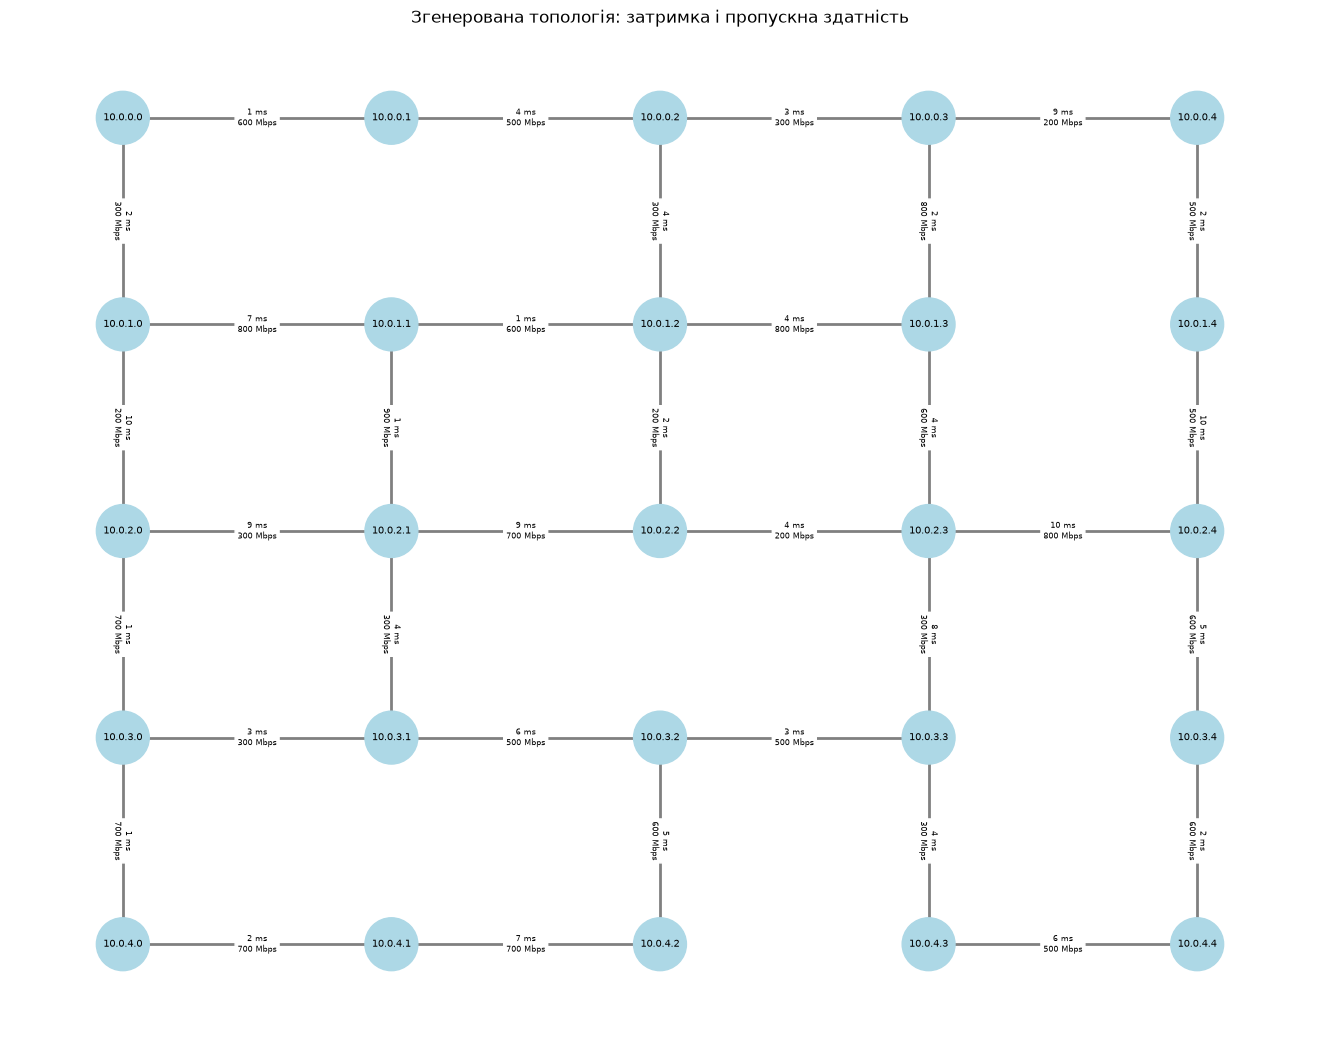

In [7]:
seed = 42
random.seed(seed)
validate_args(25, 6, 1, 10)
graph = create_graph(25, 1, 10)
remove_edges(graph, 6)
assign_channel_markings(graph, prepared['test_dataset'], seed=seed)

draw_network(graph, title='Згенерована топологія: затримка і пропускна здатність')
plt.show()

## 4. Побудова маршруту контролером

Контролер використовує саме квантовану ONNX INT8 модель. Для потоку 1 ГБ час передачі дорівнює сумі затримок каналів плюс `8000 Мбіт / мінімальна пропускна здатність маршруту`.

In [8]:
recognizer = QuantizedDigitRecognizer(prepared['int8_path'])
result = neural_network_controller(
    graph,
    start=(0, 0),
    target=(4, 4),
    recognizer=recognizer,
    payload_gb=1.0,
)
print_route_report(graph, result, payload_gb=1.0)

Потік: 1 ГБ
Маршрут: [(0, 0), (0, 1), (0, 2), (0, 3), (1, 3), (1, 2), (1, 1), (2, 1), (2, 2), (2, 3), (2, 4), (3, 4), (4, 4)]
  (0, 0) -> (0, 1): затримка=1 мс, маркування=6, розпізнано=600 Мбіт/с
  (0, 1) -> (0, 2): затримка=4 мс, маркування=5, розпізнано=500 Мбіт/с
  (0, 2) -> (0, 3): затримка=3 мс, маркування=3, розпізнано=300 Мбіт/с
  (0, 3) -> (1, 3): затримка=2 мс, маркування=8, розпізнано=800 Мбіт/с
  (1, 3) -> (1, 2): затримка=4 мс, маркування=8, розпізнано=800 Мбіт/с
  (1, 2) -> (1, 1): затримка=1 мс, маркування=6, розпізнано=600 Мбіт/с
  (1, 1) -> (2, 1): затримка=1 мс, маркування=9, розпізнано=900 Мбіт/с
  (2, 1) -> (2, 2): затримка=9 мс, маркування=7, розпізнано=700 Мбіт/с
  (2, 2) -> (2, 3): затримка=4 мс, маркування=2, розпізнано=200 Мбіт/с
  (2, 3) -> (2, 4): затримка=10 мс, маркування=8, розпізнано=800 Мбіт/с
  (2, 4) -> (3, 4): затримка=5 мс, маркування=6, розпізнано=600 Мбіт/с
  (3, 4) -> (4, 4): затримка=2 мс, маркування=6, розпізнано=600 Мбіт/с
Вузьке місце: ((2, 2)

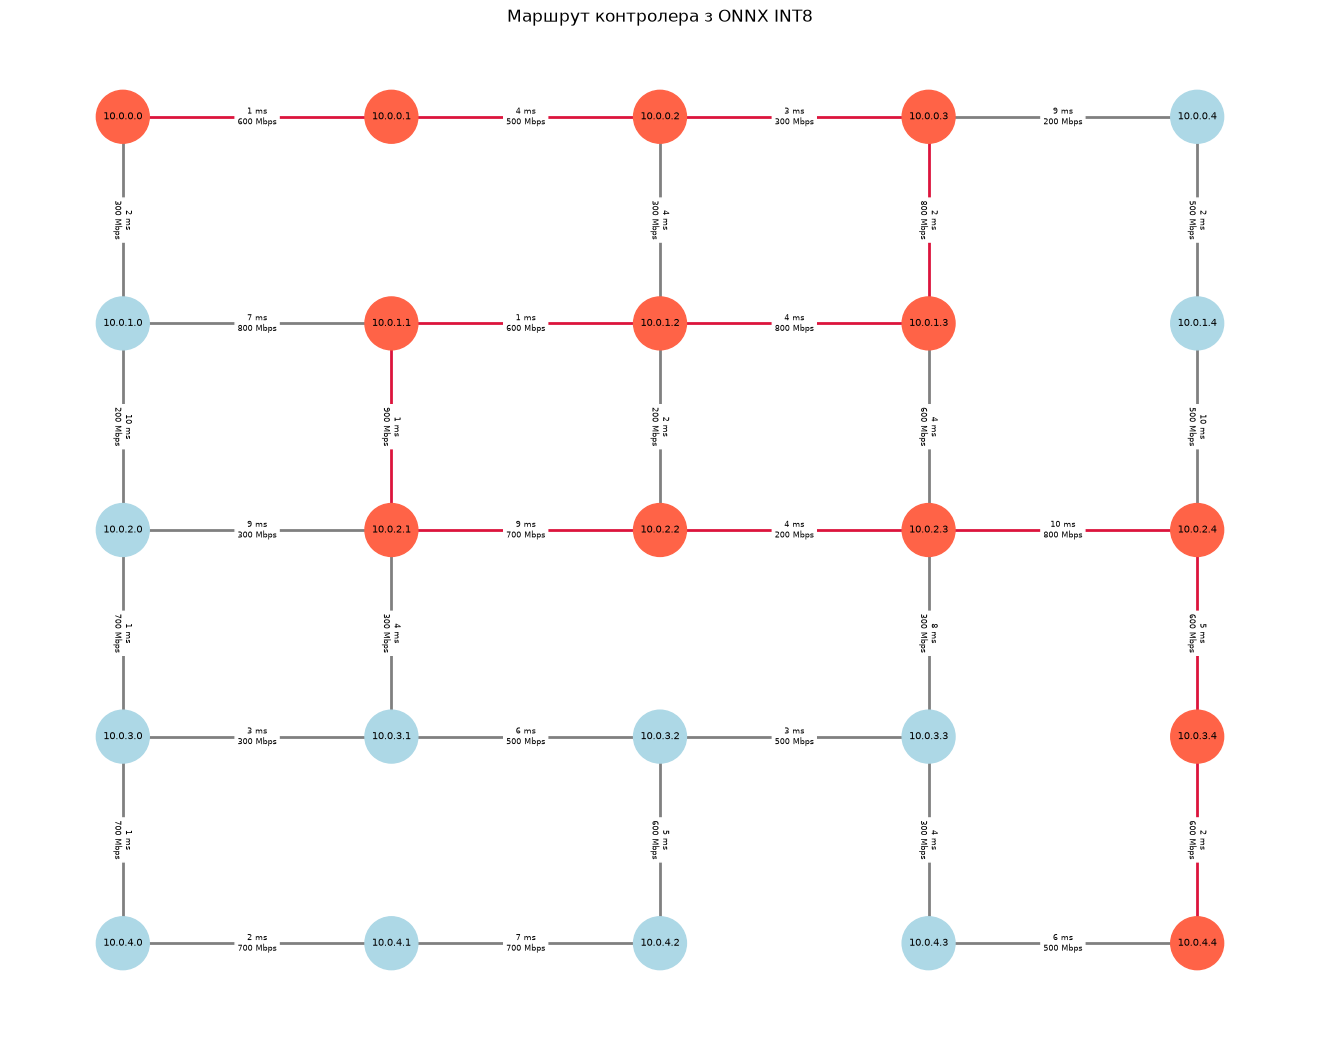

In [9]:
draw_network(graph, result['path'], 'Маршрут контролера з ONNX INT8')
plt.show()


## 5. Еталонний маршрут

Для перевірки обчислюється найкращий маршрут на повному графі з істинними пропускними здатностями. Для кожного можливого вузького місця шукається шлях із мінімальною сумою затримок, після чого вибирається мінімальний повний час передачі.

In [10]:
optimal = best_path_for_flow(
    graph,
    (0, 0),
    (4, 4),
    payload_gb=1.0,
    bandwidth_key='bandwidth_mbps',
)
print('Оптимальний час:', f'{optimal[0]:.4f} с')
print('Оптимальний маршрут:', optimal[1])
print('Вузьке місце:', optimal[2], 'Мбіт/с', optimal[3])

Оптимальний час: 26.6977 с
Оптимальний маршрут: [(0, 0), (0, 1), (0, 2), (0, 3), (1, 3), (2, 3), (2, 4), (3, 4), (4, 4)]
Вузьке місце: 300 Мбіт/с ((0, 2), (0, 3))


## Висновок

Контролер доповнено системою комп’ютерного зору. CNN розпізнає маркування каналів, ONNX забезпечує переносимий інференс, а INT8-квантування зменшує розмір моделі та змінює її продуктивність із незначним можливим впливом на точність. Час розпізнавання маркувань є значно меншим за час передачі потоку й окремо вимірюється програмою.